# Лабораторна робота №3
## Розв'язання задачі класифікації

**Мета:** виконати побудову, навчання та оцінювання моделей класифікації Logistic Regression, k-NN та SVM; проаналізувати результати за допомогою confusion matrix та метрик Precision, Recall, F1-score і ROC-AUC; порівняти моделі й обґрунтувати вибір найкращої.

Використано набір даних з ЛР1 - **Telco Customer Churn**. Цільова змінна - `Churn`: пішов клієнт від компанії (1) чи ні (0). Це задача бінарної класифікації.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Завантаження та підготовка даних

In [2]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Кількість записів:", df.shape[0])
print("Кількість стовпців:", df.shape[1])

Кількість записів: 7043
Кількість стовпців: 21


In [3]:
df = df.drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Кількість дублікатів:", df.duplicated().sum())
df = df.drop_duplicates()

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print("Кількість записів після очищення:", len(df))
print("Пропусків у TotalCharges:", df["TotalCharges"].isnull().sum())

Кількість дублікатів: 22
Кількість записів після очищення: 7021
Пропусків у TotalCharges: 11


Очищення зроблено так само, як у ЛР1: видалено `customerID`, `TotalCharges` перетворено в число, видалено дублікати, `Churn` закодовано як 1/0. Пропуски в `TotalCharges` тепер в ознаці, а не в цілі, тому рядки не видаляємо. Їх заповнимо медіаною після поділу на вибірки, всередині Pipeline.

## 2. Початковий аналіз даних

In [4]:
print("Кількість об'єктів:", df.shape[0])
print("Кількість вхідних ознак:", df.shape[1] - 1)

Кількість об'єктів: 7021
Кількість вхідних ознак: 19


In [5]:
types_table = pd.DataFrame({
    "Ознака": df.columns,
    "Тип даних": df.dtypes.astype(str).values
})
types_table

,Ознака,Тип даних
0,gender,object
1,SeniorCitizen,int64
2,Partner,object
3,Dependents,object
4,tenure,int64
5,PhoneService,object
6,MultipleLines,object
7,InternetService,object
8,OnlineSecurity,object
9,OnlineBackup,object


In [6]:
missing_table = pd.DataFrame({
    "Кількість пропусків": df.isnull().sum(),
    "Частка, %": (df.isnull().mean() * 100).round(2)
})
missing_table[missing_table["Кількість пропусків"] > 0]

,Кількість пропусків,"Частка, %"
TotalCharges,11,0.16


In [7]:
print("Кількість класів:", df["Churn"].nunique())

class_table = pd.DataFrame({
    "Кількість": df["Churn"].value_counts(),
    "Частка": df["Churn"].value_counts(normalize=True).round(3)
})
class_table

Кількість класів: 2


,Кількість,Частка
Churn,,
0,5164,0.736
1,1857,0.264


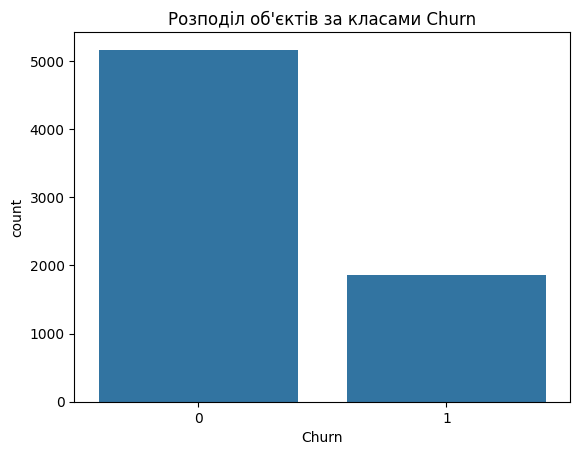

In [8]:
sns.countplot(x="Churn", data=df)
plt.title("Розподіл об'єктів за класами Churn")
plt.show()

Після очищення в наборі 7021 об'єкт і 19 вхідних ознак: 15 текстових (категоріальних) і 4 числові (`SeniorCitizen`, `tenure`, `MonthlyCharges`, `TotalCharges`). Пропуски є тільки в `TotalCharges` (11 значень, 0.16%).

Цільова змінна має 2 класи: 0 (клієнт залишився) - 5164 об'єкти (73.6%), 1 (клієнт пішов) - 1857 об'єктів (26.4%). Класи незбалансовані, приблизно 2.8 до 1. Через це Accuracy буде оманливою: модель, яка всім каже «не піде», вже має 73.6% правильних відповідей. Тому головною метрикою для вибору моделей беремо F1-score для класу 1, а поділ на вибірки робимо стратифікованим.

## 3. Формування X та y

In [9]:
y = df["Churn"]
X = df.drop(columns=["Churn"])

categorical_columns = list(X.select_dtypes(include="object").columns)
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)
print("Категоріальні ознаки:", len(categorical_columns))
print(categorical_columns)
print("Числові ознаки:", numeric_columns)

Розмір X:

 (7021, 19)
Розмір y: (7021,)
Категоріальні ознаки: 15
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Числові ознаки: ['tenure', 'MonthlyCharges', 'TotalCharges']


Категоріальні ознаки кодуються One-Hot, а числові масштабуються всередині Pipeline (пункт 5), тому тут X ще містить сирі дані. `SeniorCitizen` вже має значення 0/1, його залишаємо без змін.

## 4. Поділ на навчальну, валідаційну та тестову вибірки

In [10]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.15 / 0.85, random_state=42, stratify=y_train_val
)

print("Навчальна вибірка:", X_train.shape, y_train.shape)
print("Валідаційна вибірка:", X_val.shape, y_val.shape)
print("Тестова вибірка:", X_test.shape, y_test.shape)

Навчальна вибірка: (4914, 19) (4914,)
Валідаційна вибірка: (1053, 19) (1053,)
Тестова вибірка: (1054, 19) (1054,)


In [11]:
split_table = pd.DataFrame({
    "Весь набір": y.value_counts(normalize=True).round(3),
    "Train": y_train.value_counts(normalize=True).round(3),
    "Validation": y_val.value_counts(normalize=True).round(3),
    "Test": y_test.value_counts(normalize=True).round(3)
})
split_table

,Весь набір,Train,Validation,Test
Churn,,,,
0,0.736,0.735,0.736,0.735
1,0.264,0.265,0.264,0.265


Дані поділено 70/15/15. На навчальній вибірці моделі вчаться, на валідаційній підбираємо гіперпараметри і порівнюємо моделі, а тестову використовуємо тільки один раз в кінці для остаточної оцінки. Поділ стратифікований (`stratify`), тому частка класу 1 однакова в усіх трьох вибірках, що видно з таблиці. Це важливо, бо класи незбалансовані.

## 5. Пропуски, масштабування та кодування ознак (Pipeline)

In [12]:
missing_split = pd.DataFrame({
    "X_train": X_train.isnull().sum(),
    "X_val": X_val.isnull().sum(),
    "X_test": X_test.isnull().sum()
})
missing_split[missing_split.sum(axis=1) > 0]

,X_train,X_val,X_test
TotalCharges,8,1,2


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_columns),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_columns),
    ("senior", "passthrough", ["SeniorCitizen"])
])

preprocessor_no_scaling = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_columns),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_columns),
    ("senior", "passthrough", ["SeniorCitizen"])
])

In [14]:
X_train[numeric_columns].describe().loc[["mean", "std", "min", "max"]].round(2)

,tenure,MonthlyCharges,TotalCharges
mean,32.35,64.74,2277.79
std,24.57,30.10,2267.07
min,0.00,18.55,18.85
max,72.00,118.75,8684.80


In [15]:
preprocessor.fit(X_train)
X_train_ready = preprocessor.transform(X_train)

print("Ознак після обробки:", X_train_ready.shape[1])
print("Пропусків після обробки:", np.isnan(X_train_ready).sum())

pd.DataFrame(X_train_ready[:, :3], columns=numeric_columns).describe().loc[["mean", "std", "min", "max"]].round(2)

Ознак після обробки: 45
Пропусків після обробки: 0


,tenure,MonthlyCharges,TotalCharges
mean,0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.32,-1.53,-1.00
max,1.61,1.79,2.83


Пропуски в `TotalCharges` розподілились так: 8 у навчальній, 1 у валідаційній і 2 у тестовій вибірці.

Уся обробка зібрана в `preprocessor` (ColumnTransformer). Він потрібен, бо різні колонки обробляються по-різному:
- `num` - для `tenure`, `MonthlyCharges`, `TotalCharges` спочатку медіана замість пропусків, потім стандартизація;
- `cat` - для текстових ознак One-Hot кодування;
- `senior` - `SeniorCitizen` проходить без змін, бо вже має значення 0/1.

До масштабування числові ознаки мають дуже різні діапазони: середнє `tenure` 32.35, `MonthlyCharges` 64.74, `TotalCharges` 2277.79. Після обробки середнє 0 і стандартне відхилення 1, пропусків 0, усього 45 ознак. Тут препроцесор навчено окремо тільки для демонстрації. Моделі використовують його копії всередині своїх Pipeline, і кожен Pipeline при `fit(X_train, ...)` сам навчає препроцесор тільки на навчальній вибірці, а на валідаційній і тестовій лише застосовує його. Так витік даних неможливий. `preprocessor_no_scaling` - той самий препроцесор без скейлера, він потрібен для пункту 13.

## 6. Logistic Regression

In [16]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

logreg_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])
logreg_model.fit(X_train, y_train)

print("Logistic Regression навчено на", X_train.shape[0], "об'єктах")

Logistic Regression навчено на 4914 об'єктах


`clone(preprocessor)` створює нову ненавчену копію препроцесора для кожної моделі, щоб моделі не ділили один і той самий об'єкт. `fit` всього Pipeline навчає імпутер, скейлер, енкодер і саму модель тільки на `X_train`.

## 7. Оцінювання Logistic Regression

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

y_val_pred = logreg_model.predict(X_val)
y_val_proba = logreg_model.predict_proba(X_val)[:, 1]

print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 3))
print("Precision:", round(precision_score(y_val, y_val_pred), 3))
print("Recall:", round(recall_score(y_val, y_val_pred), 3))
print("F1-score:", round(f1_score(y_val, y_val_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_proba), 3))

Accuracy: 0.814
Precision: 0.68
Recall: 0.558
F1-score: 0.613
ROC-AUC: 0.857


In [18]:
pd.DataFrame(
    confusion_matrix(y_val, y_val_pred),
    index=["Факт 0", "Факт 1"],
    columns=["Прогноз 0", "Прогноз 1"]
)

,Прогноз 0,Прогноз 1
Факт 0,702,73
Факт 1,123,155


На валідаційній вибірці Logistic Regression має Accuracy 0.814, Precision 0.680, Recall 0.558, F1-score 0.613 і ROC-AUC 0.857.

У confusion matrix рядки - фактичний клас, стовпці - прогноз (у sklearn клас 0 іде першим): TN = 702, FP = 73, FN = 123, TP = 155. Тобто з 278 клієнтів, які справді пішли, модель знайшла 155 (Recall 56%) і пропустила 123. З 228 клієнтів, яких модель назвала такими, що підуть, правильних 155 (Precision 68%). Клас 0 модель розпізнає добре (702 з 775), а клас 1 гірше, бо прикладів цього класу втричі менше.

## 8. k-NN

In [19]:
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31]
knn_results = []

for k in k_values:
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", KNeighborsClassifier(n_neighbors=k))
    ])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)[:, 1]
    knn_results.append({
        "k": k,
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1-score": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_proba)
    })

knn_results = pd.DataFrame(knn_results)
best_k = knn_results.loc[knn_results["F1-score"].idxmax(), "k"]

print("Найкраще k за F1-score:", best_k)
knn_results.round(3)

Найкраще k за F1-score: 21


,k,Precision,Recall,F1-score,ROC-AUC
0,1,0.471,0.496,0.483,0.648
1,3,0.549,0.529,0.538,0.758
2,5,0.574,0.529,0.551,0.785
3,7,0.570,0.514,0.541,0.803
4,9,0.611,0.536,0.571,0.812
5,11,0.587,0.522,0.552,0.822
6,15,0.602,0.543,0.571,0.830
7,21,0.607,0.561,0.583,0.831
8,31,0.608,0.547,0.576,0.841


In [20]:
knn_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", KNeighborsClassifier(n_neighbors=best_k))
])
knn_model.fit(X_train, y_train)

print("k-NN навчено з k =", best_k)

k-NN навчено з k = 21


Найгірший результат при k = 1: F1 0.483 і ROC-AUC 0.648, бо модель дивиться лише на одного сусіда і підлаштовується під шум. Зі збільшенням k якість росте, найкращий F1 = 0.583 при k = 21 (Precision 0.607, Recall 0.561, ROC-AUC 0.831). При k = 31 F1 трохи падає (0.576), хоча ROC-AUC ще росте. Обрано k = 21 за F1-score.

## 9. SVM

In [21]:
from sklearn.svm import SVC

C_values = [0.01, 0.1, 1, 10]
svm_linear_results = []

for C in C_values:
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", SVC(kernel="linear", C=C))
    ])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    y_score = model.decision_function(X_val)
    svm_linear_results.append({
        "C": C,
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1-score": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_score)
    })

svm_linear_results = pd.DataFrame(svm_linear_results)
svm_linear_results.round(3)

,C,Precision,Recall,F1-score,ROC-AUC
0,0.01,0.665,0.507,0.576,0.849
1,0.10,0.662,0.522,0.584,0.847
2,1.00,0.659,0.522,0.582,0.845
3,10.00,0.659,0.514,0.578,0.845


In [22]:
svm_rbf_results = []

for C in [0.1, 1, 10]:
    for gamma in ["scale", 0.01, 0.1]:
        model = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("model", SVC(kernel="rbf", C=C, gamma=gamma))
        ])
        model.fit(X_train, y_train)
        y_pred = model.predict(X_val)
        y_score = model.decision_function(X_val)
        svm_rbf_results.append({
            "C": C,
            "gamma": gamma,
            "Precision": precision_score(y_val, y_pred),
            "Recall": recall_score(y_val, y_pred),
            "F1-score": f1_score(y_val, y_pred),
            "ROC-AUC": roc_auc_score(y_val, y_score)
        })

svm_rbf_results = pd.DataFrame(svm_rbf_results)
svm_rbf_results.round(3)

,C,gamma,Precision,Recall,F1-score,ROC-AUC
0,0.1,scale,0.695,0.417,0.521,0.828
1,0.1,0.01,0.691,0.378,0.488,0.849
2,0.1,0.1,0.695,0.417,0.521,0.822
3,1.0,scale,0.696,0.460,0.554,0.810
4,1.0,0.01,0.707,0.460,0.558,0.845
5,1.0,0.1,0.689,0.471,0.560,0.806
6,10.0,scale,0.606,0.514,0.556,0.787
7,10.0,0.01,0.698,0.457,0.552,0.830
8,10.0,0.1,0.571,0.493,0.529,0.779


In [23]:
best_linear = svm_linear_results.loc[svm_linear_results["F1-score"].idxmax()]
best_rbf = svm_rbf_results.loc[svm_rbf_results["F1-score"].idxmax()]

print("Найкраще лінійне ядро: C =", best_linear["C"], " F1 =", round(best_linear["F1-score"], 3))
print("Найкраще RBF-ядро: C =", best_rbf["C"], " gamma =", best_rbf["gamma"], " F1 =", round(best_rbf["F1-score"], 3))

if best_linear["F1-score"] >= best_rbf["F1-score"]:
    best_svm = SVC(kernel="linear", C=float(best_linear["C"]))
else:
    best_svm = SVC(kernel="rbf", C=float(best_rbf["C"]), gamma=best_rbf["gamma"])

svm_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", best_svm)
])
svm_model.fit(X_train, y_train)

print("Обрана конфігурація SVM: kernel =", best_svm.kernel, " C =", best_svm.C, " gamma =", best_svm.gamma)

Найкраще лінійне ядро: C = 0.1  F1 = 0.584
Найкраще RBF-ядро: C = 1.0  gamma = 0.1  F1 = 0.56


Обрана конфігурація SVM: kernel = linear  C = 0.1  gamma = scale


**Лінійне ядро:** F1 майже не залежить від C (від 0.576 до 0.584), ROC-AUC 0.845-0.849. Найкраще C = 0.1: F1 0.584, Precision 0.662, Recall 0.522.

**RBF-ядро:** найкраще C = 1, gamma = 0.1 з F1 0.560. При C = 0.1 модель надто сильно регуляризована, і Recall низький (0.378-0.417): вона частіше відносить клієнтів до класу 0. При C = 10 і gamma = 0.1 ROC-AUC падає до 0.779, тобто модель уже підлаштовується під навчальні дані.

RBF-ядро в жодній конфігурації не перевершило лінійне. Отже, межа між класами в цих даних близька до лінійної, і складніше ядро нічого не дає. Обрано SVM з лінійним ядром і C = 0.1. Параметр gamma для лінійного ядра не використовується, тому у виводі він лишається за замовчуванням (scale).

## 10. Confusion matrix для кожної моделі

In [24]:
models = {
    "Logistic Regression": logreg_model,
    "k-NN": knn_model,
    "SVM": svm_model
}

val_predictions = {}
val_scores = {}

for name, model in models.items():
    val_predictions[name] = model.predict(X_val)
    if name == "SVM":
        val_scores[name] = model.decision_function(X_val)
    else:
        val_scores[name] = model.predict_proba(X_val)[:, 1]

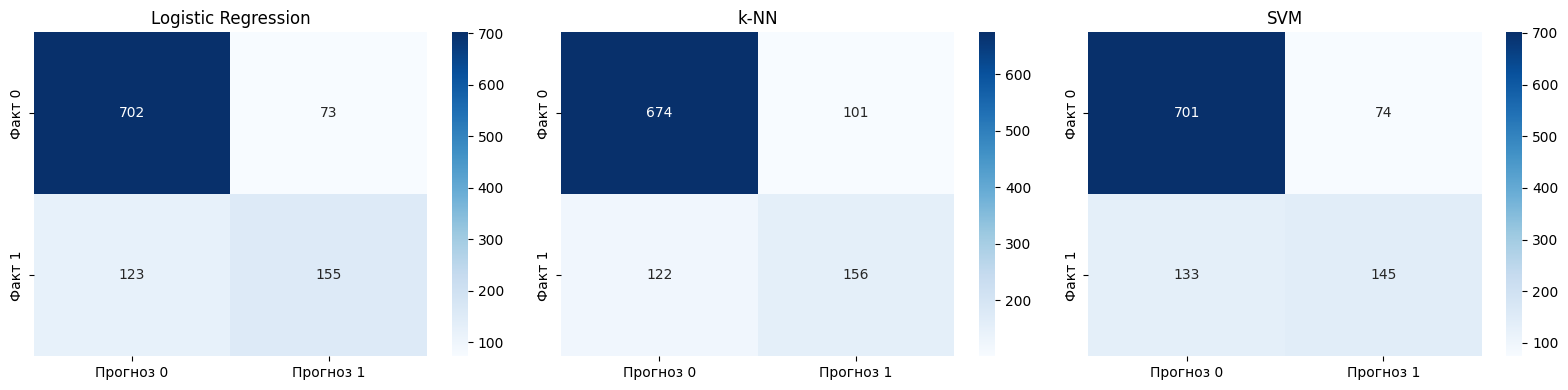

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, name in zip(axes, models.keys()):
    matrix = confusion_matrix(y_val, val_predictions[name])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Прогноз 0", "Прогноз 1"], yticklabels=["Факт 0", "Факт 1"])
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [26]:
errors_table = []

for name in models.keys():
    tn, fp, fn, tp = confusion_matrix(y_val, val_predictions[name]).ravel()
    errors_table.append({"Модель": name, "TP": tp, "TN": tn, "FP": fp, "FN": fn})

pd.DataFrame(errors_table)

,Модель,TP,TN,FP,FN
0,Logistic Regression,155,702,73,123
1,k-NN,156,674,101,122
2,SVM,145,701,74,133


| Модель | TP | TN | FP | FN |
|---|---|---|---|---|
| Logistic Regression | 155 | 702 | 73 | 123 |
| k-NN | 156 | 674 | 101 | 122 |
| SVM | 145 | 701 | 74 | 133 |

Усі моделі добре розпізнають клас 0: правильно визначено від 674 до 702 клієнтів з 775 (87-91%). З класом 1 гірше: знайдено лише від 145 до 156 з 278 клієнтів, які пішли (52-56%). В усіх моделях FN більше за FP, тобто моделі частіше пропускають клієнта, який піде, ніж помилково «записують» у відтік того, хто залишиться. Це наслідок дисбалансу класів. k-NN знаходить стільки ж клієнтів класу 1, скільки Logistic Regression (156 проти 155), але має на 28 більше хибних тривог (FP = 101). SVM пропускає найбільше клієнтів класу 1 (FN = 133).

## 11. ROC-криві

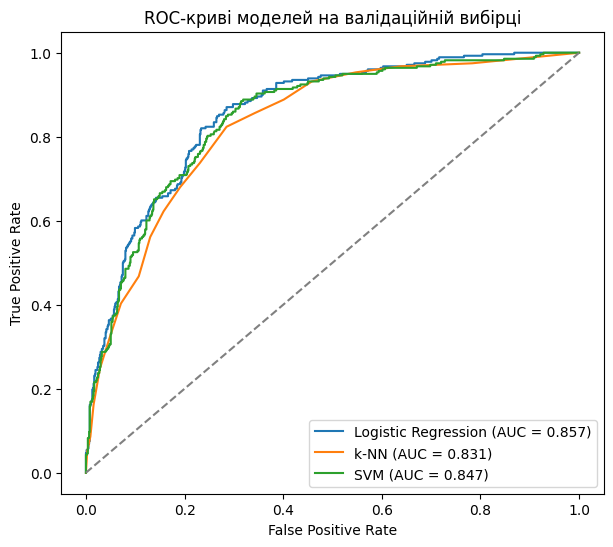

In [27]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))

for name in models.keys():
    fpr, tpr, thresholds = roc_curve(y_val, val_scores[name])
    auc = roc_auc_score(y_val, val_scores[name])
    plt.plot(fpr, tpr, label=name + " (AUC = " + str(round(auc, 3)) + ")")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.title("ROC-криві моделей на валідаційній вибірці")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

Найбільша площа під ROC-кривою в Logistic Regression (0.857), далі SVM (0.847) і k-NN (0.831). Криві Logistic Regression і SVM майже збігаються, бо обидві моделі будують лінійну межу. Крива k-NN нижча, особливо в середній частині. Усі три криві значно вище за діагональ (випадкове вгадування, AUC = 0.5), тобто всі моделі добре розрізняють класи.

## 12. Порівняння моделей

In [28]:
comparison = []

for name in models.keys():
    comparison.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_val, val_predictions[name]),
        "Precision": precision_score(y_val, val_predictions[name]),
        "Recall": recall_score(y_val, val_predictions[name]),
        "F1-score": f1_score(y_val, val_predictions[name]),
        "ROC-AUC": roc_auc_score(y_val, val_scores[name])
    })

comparison_table = pd.DataFrame(comparison)
comparison_table.round(3)

,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.814,0.680,0.558,0.613,0.857
1,k-NN,0.788,0.607,0.561,0.583,0.831
2,SVM,0.803,0.662,0.522,0.584,0.847


Logistic Regression найкраща за Accuracy (0.814), Precision (0.680), F1-score (0.613) і ROC-AUC (0.857). За Recall k-NN трохи кращий (0.561 проти 0.558), але різниця в один об'єкт. SVM за F1 майже як k-NN (0.584 проти 0.583), але має вищі Precision і ROC-AUC і нижчий Recall.

Accuracy у всіх моделей виглядає високою (0.788-0.814), але це оманливо: проста модель, яка завжди каже «клас 0», мала б 0.736. F1-score (0.58-0.61) значно чесніше показує, наскільки добре моделі знаходять клієнтів, які йдуть.

## 13. Вплив масштабування на k-NN та SVM

In [29]:
knn_no_scaling = Pipeline([
    ("preprocessor", clone(preprocessor_no_scaling)),
    ("model", KNeighborsClassifier(n_neighbors=best_k))
])
svm_no_scaling = Pipeline([
    ("preprocessor", clone(preprocessor_no_scaling)),
    ("model", clone(best_svm))
])

knn_no_scaling.fit(X_train, y_train)
svm_no_scaling.fit(X_train, y_train)

scaling_table = []

for name, model in [("k-NN з масштабуванням", knn_model), ("k-NN без масштабування", knn_no_scaling),
                    ("SVM з масштабуванням", svm_model), ("SVM без масштабування", svm_no_scaling)]:
    y_pred = model.predict(X_val)
    if "SVM" in name:
        y_score = model.decision_function(X_val)
    else:
        y_score = model.predict_proba(X_val)[:, 1]
    scaling_table.append({
        "Модель": name,
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred),
        "F1-score": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_score)
    })

pd.DataFrame(scaling_table).round(3)

,Модель,Precision,Recall,F1-score,ROC-AUC
0,k-NN з масштабуванням,0.607,0.561,0.583,0.831
1,k-NN без масштабування,0.650,0.374,0.475,0.777
2,SVM з масштабуванням,0.662,0.522,0.584,0.847
3,SVM без масштабування,0.706,0.450,0.549,0.821


Без масштабування k-NN погіршився найбільше: F1 впав з 0.583 до 0.475, Recall з 0.561 до 0.374, ROC-AUC з 0.831 до 0.777. k-NN рахує відстані, а без масштабування `TotalCharges` (значення до 8685) повністю домінує у відстані, і решта ознак майже не враховується.

SVM теж погіршився: F1 з 0.584 до 0.549, Recall з 0.522 до 0.450, ROC-AUC з 0.847 до 0.821. Крім того, без масштабування SVM навчався помітно довше, бо алгоритму важче знайти розділювальну площину, коли ознаки в різних масштабах. Отже, для обох методів масштабування обов'язкове, а для k-NN особливо.

## 14. Вплив параметрів моделей

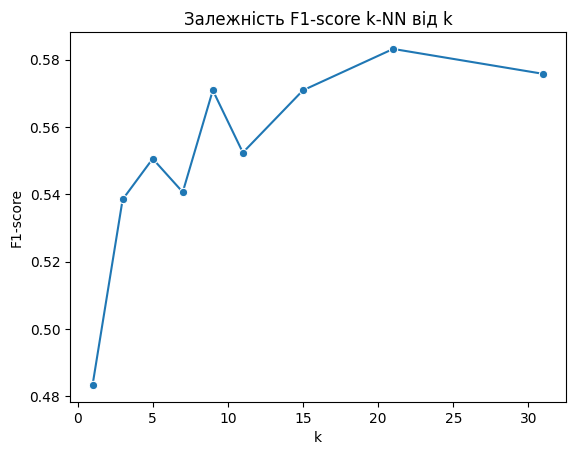

In [30]:
sns.lineplot(x="k", y="F1-score", data=knn_results, marker="o")
plt.title("Залежність F1-score k-NN від k")
plt.show()

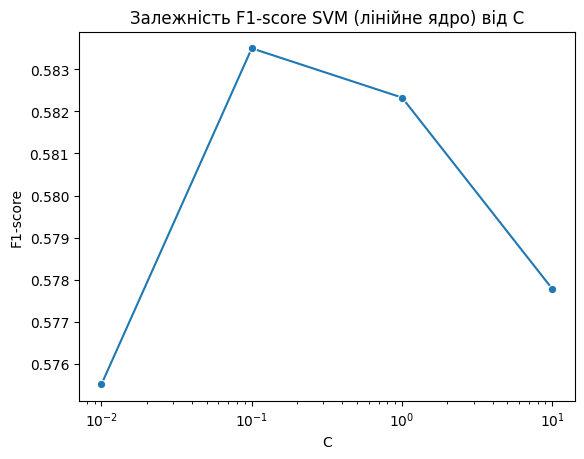

In [31]:
sns.lineplot(x="C", y="F1-score", data=svm_linear_results, marker="o")
plt.xscale("log")
plt.title("Залежність F1-score SVM (лінійне ядро) від C")
plt.show()

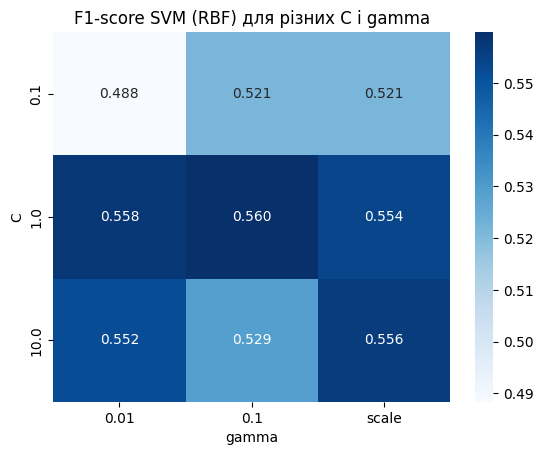

In [32]:
rbf_table = svm_rbf_results.pivot(index="C", columns="gamma", values="F1-score")

sns.heatmap(rbf_table, annot=True, fmt=".3f", cmap="Blues")
plt.title("F1-score SVM (RBF) для різних C і gamma")
plt.show()

**k для k-NN.** При k = 1 модель найгірша (F1 0.483), бо реагує на шум окремих точок. Зі збільшенням k F1 росте до 0.583 при k = 21, а при k = 31 трохи знижується: занадто велике k «розмиває» локальну структуру даних. Невеликі коливання (k = 7, 11) пов'язані з обмеженим розміром валідаційної вибірки.

**C для лінійного SVM.** F1 змінюється дуже мало (0.576-0.584), максимум при C = 0.1. Для цих даних сила регуляризації лінійного SVM майже не важлива.

**C і gamma для RBF.** Мале C = 0.1 дає недонавчання (F1 0.488-0.521, низький Recall). C = 1 найкраще (F1 0.554-0.560). При C = 10 і gamma = 0.1 F1 знижується до 0.529, а ROC-AUC до 0.779: велике gamma робить вплив кожної точки дуже локальним, і разом зі слабкою регуляризацією модель перенавчається. Комбінація C = 0.1 і gamma = 0.01 найгірша (F1 0.488), бо модель занадто «гладка».

## 15. Вибір найкращої моделі

Найбільш придатною обрано **Logistic Regression** (`max_iter=1000`, параметри регуляризації за замовчуванням):
- **метрики:** найвищі на валідації F1-score (0.613), Precision (0.680) і ROC-AUC (0.857), Recall практично такий самий, як у k-NN;
- **характер помилок:** вона знаходить стільки ж клієнтів класу 1, скільки k-NN (155 проти 156), але має найменше хибних тривог (FP = 73 проти 101 у k-NN), і пропускає менше клієнтів класу 1, ніж SVM (FN = 123 проти 133);
- **властивості даних:** більшість ознак - це One-Hot стовпці плюс 3 числові, і межа між класами близька до лінійної (лінійний SVM кращий за RBF). Тому складніші методи не дають виграшу.

Додаткові переваги Logistic Regression: вона швидка, проста, її коефіцієнти можна інтерпретувати, і вона видає ймовірність відтоку. Якщо компанії важливіше не пропустити клієнта, поріг 0.5 можна знизити і так підняти Recall.

## 16. Остаточне оцінювання на тестовій вибірці

In [33]:
best_name = comparison_table.loc[comparison_table["F1-score"].idxmax(), "Модель"]
final_model = clone(models[best_name])

X_train_full = pd.concat([X_train, X_val])
y_train_full = pd.concat([y_train, y_val])

final_model.fit(X_train_full, y_train_full)

y_test_pred = final_model.predict(X_test)
if best_name == "SVM":
    y_test_score = final_model.decision_function(X_test)
else:
    y_test_score = final_model.predict_proba(X_test)[:, 1]

print("Обрана модель:", best_name)
print("Розмір train + val:", X_train_full.shape)
print("Precision:", round(precision_score(y_test, y_test_pred), 3))
print("Recall:", round(recall_score(y_test, y_test_pred), 3))
print("F1-score:", round(f1_score(y_test, y_test_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_score), 3))

Обрана модель: Logistic Regression
Розмір train + val: (5967, 19)
Precision: 0.66
Recall: 0.556
F1-score: 0.603
ROC-AUC: 0.839


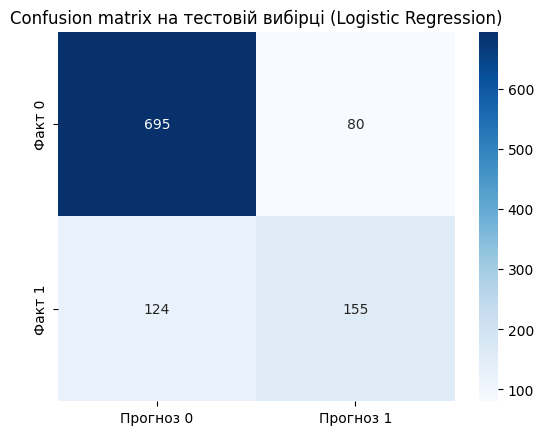

In [34]:
sns.heatmap(confusion_matrix(y_test, y_test_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Прогноз 0", "Прогноз 1"], yticklabels=["Факт 0", "Факт 1"])
plt.title("Confusion matrix на тестовій вибірці (" + best_name + ")")
plt.show()

Logistic Regression перенавчено на об'єднаних навчальній і валідаційній вибірках (5967 об'єктів; препроцесор усередині Pipeline при цьому теж навчився на train + val, тестова вибірка не використовувалась). На тестовій вибірці: Precision 0.660, Recall 0.556, F1-score 0.603, ROC-AUC 0.839. Це трохи нижче, ніж на валідації (F1 0.613, ROC-AUC 0.857), але різниця невелика, отже модель не підлаштована під валідаційну вибірку і стабільно працює на нових даних.

Confusion matrix на тесті: TN = 695, FP = 80, FN = 124, TP = 155. З 279 клієнтів, які пішли, модель знайшла 155, а з 775 клієнтів, що залишились, помилково віднесла до відтоку 80. Характер помилок такий самий, як на валідації: пропущених клієнтів класу 1 (FN) більше, ніж хибних тривог (FP).

## 17. Висновки

- **Принципи роботи.** Logistic Regression рахує лінійну комбінацію ознак і перетворює її сигмоїдою на ймовірність класу 1. k-NN не будує явної моделі, а відносить об'єкт до класу більшості з k найближчих сусідів за відстанню. SVM шукає розділювальну гіперплощину з максимальним зазором, а за допомогою ядер (RBF) може будувати нелінійні межі.
- **Якість моделей на валідації.** Logistic Regression: F1 0.613, ROC-AUC 0.857. SVM (лінійне ядро, C = 0.1): F1 0.584, ROC-AUC 0.847. k-NN (k = 21): F1 0.583, ROC-AUC 0.831. Усі моделі добре розпізнають клієнтів, які залишаються, і гірше тих, хто йде: Recall лише 0.52-0.56.
- **Причини відмінностей.** Межа між класами в цих даних близька до лінійної, тому лінійні моделі (Logistic Regression, лінійний SVM) працюють найкраще, а RBF-ядро не дало виграшу. k-NN гірший, бо в просторі з 45 ознак, більшість з яких бінарні One-Hot, відстані менш інформативні. Він також найбільше залежить від масштабування (без нього F1 падає до 0.475). Низький Recall у всіх моделей пояснюється дисбалансом класів (26.4% клієнтів класу 1).
- **Вибір.** Для цього набору даних найкраще підходить Logistic Regression: найвищі F1, Precision і ROC-AUC, найменше хибних тривог, простота та інтерпретованість. На тестовій вибірці вона показала F1 0.603 і ROC-AUC 0.839, що близько до валідаційних результатів.